[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_5_Regresion_Logistica_DILI.ipynb)

# Fase 5. Regresión logística para la clase DILI

En esta fase uso la etiqueta DILI como variable binaria: 1 indica clasificación positiva y 0 negativa. Considero los descriptores numéricos de RDKit, excepto MolLogP y LipinskiViolations. Selecciono en entrenamiento hasta veinte variables con mayor asociación bivariada con DILI y retiro las que tienen correlación absoluta de Spearman de 0,90 o más. Evalúo el modelo en prueba.

## 5.1. Lectura de los datos

In [1]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
datos = dilist.merge(estructuras, on='CompoundName', how='left')  # Uno las etiquetas con el estado de búsqueda.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /workspace/scratch/b597cb51ba0f/run_outputs/datos_dili
Descriptores numéricos disponibles: 218


## 5.2. Preparación y ajuste

Reduzco la redundancia entre predictores con información de entrenamiento. Ajusto la imputación y la estandarización usando únicamente train, y aplico el mismo ajuste a test.

In [2]:
# Importo herramientas para preparar y ajustar la regresión logística.
from sklearn.impute import SimpleImputer  # Completo posibles valores ausentes.
from sklearn.preprocessing import StandardScaler  # Estandarizo los predictores.
from sklearn.linear_model import LogisticRegression  # Ajusto la regresión logística.

# Selecciono descriptores sin MolLogP ni incumplimientos que dependen de esa variable.
columnas_excluir = ['MolLogP', 'LipinskiViolations', 'DILI', 'DILIST_ID']  # Evito LogP, la clase y los identificadores.
predictores = [variable for variable in DESCRIPTORES if variable not in columnas_excluir and train_df[variable].nunique(dropna=True) > 1]  # Uso descriptores no constantes.
print('Descriptores candidatos:', len(predictores))  # Informo el tamaño inicial del catálogo.

# Reviso las asociaciones bivariadas con DILI usando solo entrenamiento.
asociacion = train_df[predictores + ['DILI']].corr(method='spearman')['DILI'].drop('DILI').dropna().abs().sort_values(ascending=False)  # Ordeno la asociación absoluta.
candidatos = asociacion.head(20).index.tolist()  # Limito el modelo a veinte candidatos.
print('Candidatos con mayor asociación a DILI:', len(candidatos))  # Muestro el número seleccionado.

# Quito variables redundantes entre los candidatos.
correlacion = train_df[candidatos].corr(method='spearman').abs()  # Calculo correlación absoluta.
seleccionados = []  # Creo la lista de predictores finales.
for variable in candidatos:  # Reviso candidatos en orden de asociación.
    if not any(correlacion.loc[variable, otra] >= 0.90 for otra in seleccionados):  # Compruebo redundancia.
        seleccionados.append(variable)  # Conservo variables por debajo del umbral.
print('Descriptores que usaré:', seleccionados)  # Informo el conjunto final.

# Preparo la variable objetivo y ajusto transformaciones usando solo train.
y_train = train_df['DILI'].astype(int)  # Defino las etiquetas de entrenamiento.
y_test = test_df['DILI'].astype(int)  # Defino las etiquetas de prueba.
imputador = SimpleImputer(strategy='median')  # Creo imputación por mediana.
imputador.fit(train_df[seleccionados])  # Aprendo medianas solo en train.
X_train_imp = imputador.transform(train_df[seleccionados])  # Transformo train.
X_test_imp = imputador.transform(test_df[seleccionados])  # Aplico medianas de train a test.
escalador = StandardScaler()  # Creo el escalador.
escalador.fit(X_train_imp)  # Aprendo medias y desviaciones solo con train.
X_train = escalador.transform(X_train_imp)  # Estandarizo train.
X_test = escalador.transform(X_test_imp)  # Transformo test con el mismo ajuste.

# Ajusto el modelo y pondero las clases según su frecuencia.
modelo = LogisticRegression(class_weight='balanced', max_iter=3000, random_state=42)  # Defino el clasificador.
modelo.fit(X_train, y_train)  # Ajusto el modelo con entrenamiento.


Descriptores candidatos: 211
Candidatos con mayor asociación a DILI: 20
Descriptores que usaré: ['FractionCSP3', 'BCUT2D_LOGPLOW', 'fr_Al_OH', 'SMR_VSA6', 'SlogP_VSA2', 'fr_Ndealkylation1', 'BCUT2D_MRHI', 'fr_quatN', 'PEOE_VSA1', 'NumAtomStereoCenters', 'VSA_EState9', 'BCUT2D_CHGLO', 'SlogP_VSA10', 'SlogP_VSA8', 'fr_Ndealkylation2', 'fr_guanido', 'SMR_VSA5', 'NumRadicalElectrons', 'PEOE_VSA13']


## 5.3. Evaluación e interpretación

Presento la matriz de confusión, accuracy, precision, recall, F1 y AUC-ROC. También convierto los coeficientes en odds ratios. La interpretación se refiere a asociaciones en estos datos, no a causalidad.

Matriz de confusión, filas reales y columnas predichas:
[[46 45]
 [59 87]]
Un odds ratio mayor que 1 se asocia con mayores odds de DILI positiva; menor que 1, con menores odds.


,valor
accuracy,0.561
precision,0.659
recall,0.596
F1,0.626
AUC-ROC,0.606


,coeficiente,odds_ratio
NumAtomStereoCenters,1.002,2.723
BCUT2D_LOGPLOW,0.376,1.457
SlogP_VSA8,0.248,1.281
PEOE_VSA13,0.193,1.213
BCUT2D_MRHI,0.192,1.212
SlogP_VSA10,0.152,1.164
SMR_VSA6,0.075,1.078
VSA_EState9,-0.047,0.954
SMR_VSA5,-0.052,0.949
fr_Ndealkylation2,-0.128,0.880


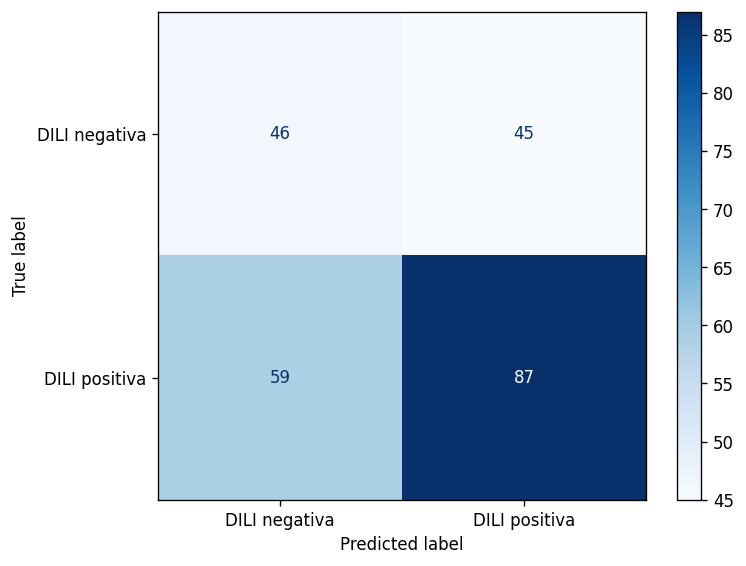

In [3]:
import matplotlib.pyplot as plt  # Dibujo la evaluación del modelo.
# Importo las métricas para evaluar la clasificación.
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay  # Cargo medidas de evaluación.

# Calculo las clases y probabilidades predichas para test.
prediccion = modelo.predict(X_test)  # Predigo la clase DILI.
probabilidad = modelo.predict_proba(X_test)[:, 1]  # Extraigo la probabilidad de la clase positiva.
matriz = confusion_matrix(y_test, prediccion, labels=[0, 1])  # Calculo verdaderos y falsos positivos/negativos.
metricas = {'accuracy': accuracy_score(y_test, prediccion), 'precision': precision_score(y_test, prediccion, zero_division=0), 'recall': recall_score(y_test, prediccion, zero_division=0), 'F1': f1_score(y_test, prediccion, zero_division=0), 'AUC-ROC': roc_auc_score(y_test, probabilidad)}  # Calculo indicadores de clasificación.
print('Matriz de confusión, filas reales y columnas predichas:')  # Explico el formato.
print(matriz)  # Muestro la matriz.
display(pd.Series(metricas, name='valor').to_frame().round(3))  # Muestro las métricas.

# Visualizo la matriz de confusión con sus etiquetas.
ConfusionMatrixDisplay(matriz, display_labels=['DILI negativa', 'DILI positiva']).plot(cmap='Blues')  # Represento los cuatro resultados.
plt.tight_layout()  # Ajusto la visualización.
plt.show()  # Muestro la figura.

# Calculo odds ratios por un aumento de una desviación estándar.
odds = pd.DataFrame({'coeficiente': modelo.coef_[0], 'odds_ratio': np.exp(modelo.coef_[0])}, index=seleccionados)  # Organizo coeficientes.
display(odds.sort_values('odds_ratio', ascending=False).round(3))  # Ordeno odds ratios.
print('Un odds ratio mayor que 1 se asocia con mayores odds de DILI positiva; menor que 1, con menores odds.')  # Explico la lectura.


## Lectura del resultado

Valoro el recall de la clase positiva junto con precision y F1, porque un único porcentaje de accuracy podría ocultar errores en una clase. Reviso también AUC-ROC y la matriz de confusión. Los odds ratios describen cambios relativos en odds, manteniendo constantes las demás variables del modelo.